### TRABAJO PRACTICO #1

Hipótesis:
1. Los suscritores que tiene baja cantidad de horas mensuales de visualización se cancelan mas.
2. Los suscriptores con mas días sin loguearse, cancelan mas.
3. Los suscriptores que NO pagan con tarjetas de Credito|Debito|Paypal, cancelan mas.
4. Los suscriptores con mas perfiles, cancelan menos.
5. Los suscriptores con mayor edad, cancelan menos.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga del dataset y primera interpretación

Fuente: https://www.kaggle.com/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics

In [4]:
df=pd.read_csv("netflix_customer_churn.csv")
df

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi


Dimensión

In [71]:
df.shape  ## Tamaño del dataset

(5000, 14)

Exploración de distintos segmentos

In [72]:
### Exploración de segmentos al azar ###
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [73]:
df.tail()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi
4999,82aeef39-ddb0-40ad-bae1-5c436e0cf042,57,Male,Basic,1.62,17,Africa,Mobile,8.99,1,Crypto,2,0.09,Action


In [75]:
df.sample(10,random_state=42)

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
1501,815bed6b-02ad-465b-9f68-c07c508524ce,39,Other,Basic,9.96,22,South America,Tablet,8.99,0,Gift Card,5,0.43,Drama
2586,2f55007a-9682-4109-8431-2fa060e85673,18,Female,Standard,0.25,37,Africa,Laptop,13.99,1,Debit Card,5,0.01,Sci-Fi
2653,89931699-5ba5-434a-8dca-32e18d7dbd4b,19,Female,Standard,8.54,6,Africa,TV,13.99,0,Credit Card,3,1.22,Romance
1055,9b57e510-576f-4fce-87b1-8f4d2b614820,34,Male,Premium,13.49,51,South America,Tablet,17.99,1,Debit Card,1,0.26,Horror
705,7ee9fa15-81b6-4b1b-a841-eec8b03d8b1e,29,Male,Basic,24.18,59,Africa,Laptop,8.99,1,Credit Card,1,0.40,Documentary
106,fa19687b-872c-4163-a900-59f1b4098ed9,49,Female,Basic,2.90,46,Asia,Mobile,8.99,1,Debit Card,2,0.06,Horror
589,6ee480c7-c4c3-4dcd-abbc-d46b49f0b6dd,62,Other,Standard,23.97,60,Africa,Desktop,13.99,1,Crypto,1,0.39,Horror
2468,3a85cb4f-fbe6-43cd-9e48-561e968a38ba,25,Other,Basic,6.38,58,Europe,Desktop,8.99,1,PayPal,3,0.11,Documentary
2413,437ee4e8-fc39-4e80-99a5-3e8aa461522a,68,Male,Standard,24.08,58,South America,Laptop,13.99,0,Gift Card,2,0.41,Comedy
1600,c20324f1-17e6-4484-b4bc-8671f89e607e,65,Female,Premium,10.55,25,Africa,Laptop,17.99,0,Gift Card,5,0.41,Drama


Tipo de variables y recorrido

In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 920.1

In [77]:
df.churned.unique()  ## TARGET variable categórica

array([1, 0])

In [78]:
df.age.unique()  #variable numérica discreta

array([51, 47, 27, 53, 56, 58, 48, 45, 32, 26, 28, 49, 39, 46, 68, 21, 60,
       70, 36, 55, 24, 30, 69, 67, 23, 57, 35, 22, 34, 19, 25, 54, 31, 42,
       63, 66, 38, 65, 43, 64, 62, 41, 18, 61, 37, 20, 50, 33, 59, 29, 52,
       40, 44])

In [79]:
df.gender.unique() #variable categórica nominal

<ArrowStringArray>
['Other', 'Female', 'Male']
Length: 3, dtype: str

In [80]:
df.subscription_type.unique()    #variable categórica ordinal

<ArrowStringArray>
['Basic', 'Standard', 'Premium']
Length: 3, dtype: str

In [103]:
np.set_printoptions(suppress=True, edgeitems=5)
np.sort(df.watch_hours.unique())                 #variable numérica continua

array([  0.01,   0.02,   0.03,   0.04,   0.05, ...,  89.83,  92.07,
        98.42, 101.06, 110.4 ], shape=(2343,))

In [86]:
np.sort(df.last_login_days.unique())  #variable numérica discreta

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60])

In [88]:
df.region.unique()  #variable categórica nominal

<ArrowStringArray>
['Africa', 'Europe', 'Asia', 'Oceania', 'South America', 'North America']
Length: 6, dtype: str

In [89]:
df.device.unique() #variable categórica nominal

<ArrowStringArray>
['TV', 'Mobile', 'Laptop', 'Desktop', 'Tablet']
Length: 5, dtype: str

In [91]:
df.monthly_fee.unique() #variable categórica ordinal. Ya que está relacionada con subscription_type

array([ 8.99, 13.99, 17.99])

In [93]:
df.payment_method.unique() #variabel categórica nominal

<ArrowStringArray>
['Gift Card', 'Crypto', 'Debit Card', 'PayPal', 'Credit Card']
Length: 5, dtype: str

In [96]:
np.sort(df.number_of_profiles.unique())  #variable numérica discreta

array([1, 2, 3, 4, 5])

In [101]:
np.set_printoptions(suppress=True, edgeitems=5)
np.sort(df.avg_watch_time_per_day.unique())         #varialble numércia continua

array([ 0.  ,  0.01,  0.02,  0.03,  0.04, ..., 32.81, 32.88, 34.53, 52.8 ,
       98.42], shape=(505,))

In [105]:
df.favorite_genre.unique()  #variable categórica nominal

<ArrowStringArray>
['Action', 'Sci-Fi', 'Drama', 'Horror', 'Romance', 'Comedy', 'Documentary']
Length: 7, dtype: str

# Limpieza e Integridad

In [12]:
df.shape

(5000, 14)

In [106]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 920.1

In [107]:
df.customer_id.nunique()

5000

In [111]:
df.customer_id.head()

0    a9b75100-82a8-427a-a208-72f24052884a
1    49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b
2    4d71f6ce-fca9-4ff7-8afa-197ac24de14b
3    d3c72c38-631b-4f9e-8a0e-de103cad1a7d
4    4e265c34-103a-4dbb-9553-76c9aa47e946
Name: customer_id, dtype: str

In [112]:
df.customer_id.tail()

4995    44f3ba44-b95d-4e50-a786-bac4d06f4a43
4996    18779bcb-ba2b-41da-b751-e70b812061ec
4997    3f32e8c5-615b-4a3b-a864-db2688f7834f
4998    7b0ad82d-6571-430e-90f4-906259e0e89c
4999    82aeef39-ddb0-40ad-bae1-5c436e0cf042
Name: customer_id, dtype: str

customer_id tiene valores en todas las filas y son únicos

Todas las filas del dataset tienen valores para cada variable

Los recorridos de las variables se corresponden con su tipo y no se detectan valores anómalos.

# Análisis exploratorio (EDA)

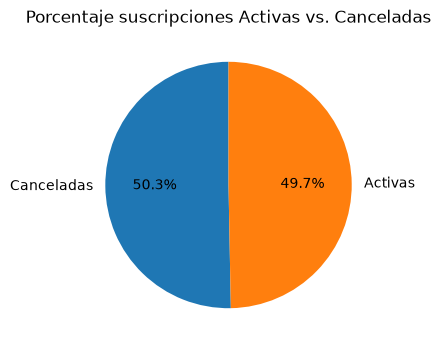

In [116]:
## Clientes activos vs. cancelados
## La proporción aprox. 50% vs 50% de Activos y Cancelados justifica en análisis para la identificación de factores involucrados
plt.figure(figsize=(6,4))
churned_count = df.churned.value_counts(normalize=True)*100
plt.pie(churned_count, labels=["Canceladas","Activas"], autopct="%1.1f%%", startangle=90)
plt.title("Porcentaje suscripciones Activas vs. Canceladas")
plt.show()

In [122]:
#buscar valores atípicos (outliers)
# se observan las variables watch_hours, avg_watch_time_per_day con valores atípicos
# Para el caso de watch_hours: los valores en (19,03875,110,40]
# PAra el caso de avg_watch_time_per_day; los valores en (0,95,98,42]
df.describe(include="all")

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
count,5000,5000.000000,5000,5000,5000.000000,5000.000000,5000,5000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000
unique,5000,NaN,3,3,NaN,NaN,6,5,NaN,NaN,5,NaN,NaN,7
top,a9b75100-82a8-427a-a208-72f24052884a,NaN,Female,Premium,NaN,NaN,South America,Tablet,NaN,NaN,Debit Card,NaN,NaN,Drama
freq,1,NaN,1711,1693,NaN,NaN,873,1048,NaN,NaN,1030,NaN,NaN,731
mean,NaN,43.847400,NaN,NaN,11.649450,30.089800,NaN,NaN,13.683400,0.503000,NaN,3.024400,0.874800,NaN
std,NaN,15.501128,NaN,NaN,12.014654,17.536078,NaN,NaN,3.692062,0.500041,NaN,1.415841,2.619824,NaN
min,NaN,18.000000,NaN,NaN,0.010000,0.000000,NaN,NaN,8.990000,0.000000,NaN,1.000000,0.000000,NaN
25%,NaN,30.000000,NaN,NaN,3.337500,15.000000,NaN,NaN,8.990000,0.000000,NaN,2.000000,0.110000,NaN
50%,NaN,44.000000,NaN,NaN,8.000000,30.000000,NaN,NaN,13.990000,1.000000,NaN,3.000000,0.290000,NaN
75%,NaN,58.000000,NaN,NaN,16.030000,45.000000,NaN,NaN,17.990000,1.000000,NaN,4.000000,0.720000,NaN


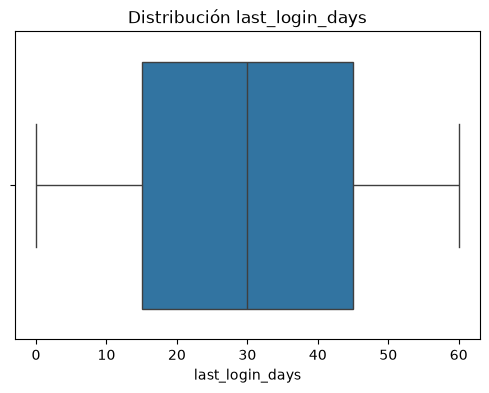

In [119]:
### Distribución last_login_days
plt.figure(figsize=(6,4))
dist_whours=sns.boxplot(data=df, x="last_login_days")
dist_whours.set_title("Distribución last_login_days")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

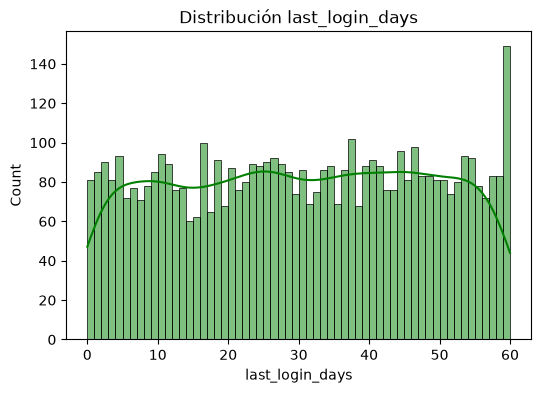

In [135]:
## last_login_days con distribución uniforme
plt.figure(figsize=(6,4))
sns.histplot(data=df,x="last_login_days",bins=60,kde=True,color="green",edgecolor="black")
plt.title("Distribución last_login_days")
plt.show

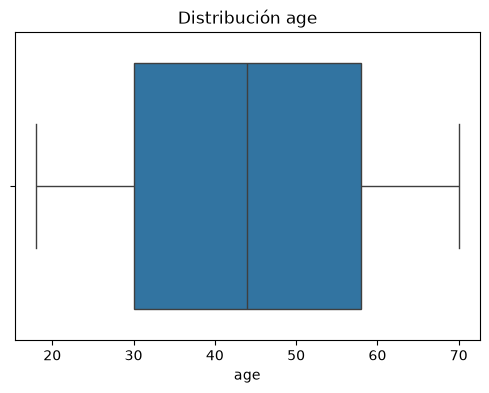

In [120]:
### Distribución age
plt.figure(figsize=(6,4))
dist_whours=sns.boxplot(data=df, x="age")
dist_whours.set_title("Distribución age")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

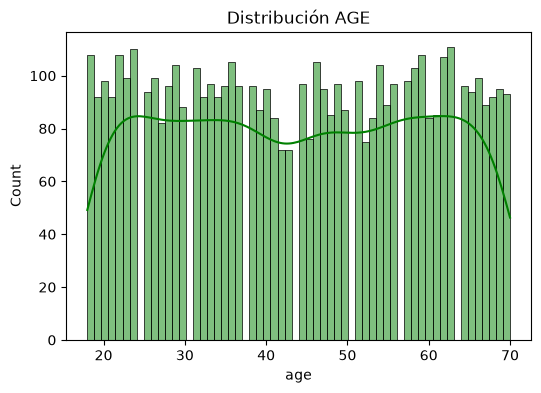

In [134]:
## AGE con distribución uniforme
plt.figure(figsize=(6,4))
sns.histplot(data=df,x="age",bins=60,kde=True,color="green",edgecolor="black")
plt.title("Distribución AGE")
plt.show

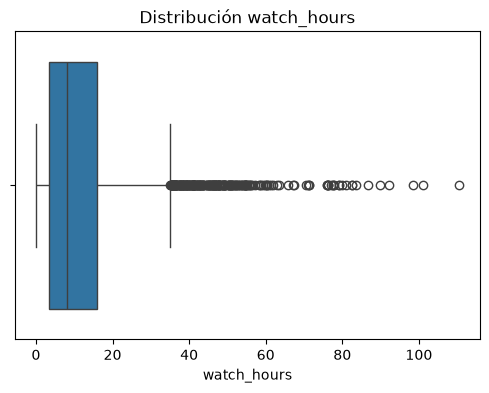

In [117]:
### Distribución watch_hours
plt.figure(figsize=(6,4))
dist_whours=sns.boxplot(data=df, x="watch_hours")
dist_whours.set_title("Distribución watch_hours")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

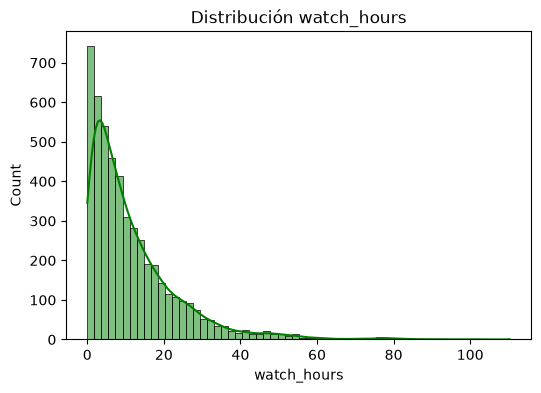

In [136]:
## watch_hours distribucién asimétrica positva
plt.figure(figsize=(6,4))
sns.histplot(data=df,x="watch_hours",bins=60,kde=True,color="green",edgecolor="black")
plt.title("Distribución watch_hours")
plt.show

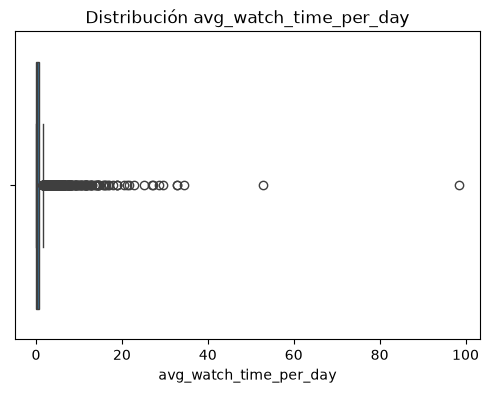

In [118]:
### Distribución avg_watch_time_per_day
plt.figure(figsize=(6,4))
dist_whours=sns.boxplot(data=df, x="avg_watch_time_per_day")
dist_whours.set_title("Distribución avg_watch_time_per_day")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

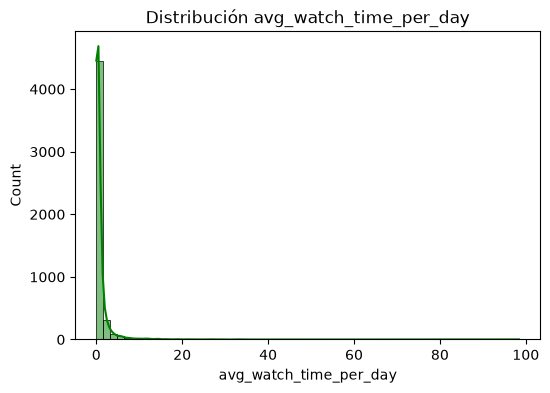

In [138]:
## avg_watch_time_per_day distribucién asimétrica positva
plt.figure(figsize=(6,4))
sns.histplot(data=df,x="avg_watch_time_per_day",bins=60,kde=True,color="green",edgecolor="black")
plt.title("Distribución avg_watch_time_per_day")
plt.show

Correlación entre variables

Las variables subscription_type - monthly_fee, estan directamente correlacionadas

La variable watch_hours denota el tiempo de consumo de streaming mensual y por ende está relacionada con avg_watch_time_per_day. A los efectos de este análisis se tomará únicamente la primera, para incluir el factor consumo, como objeto de análisis sobre la variable objetivo.

In [6]:
df.columns

Index(['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours',
       'last_login_days', 'region', 'device', 'monthly_fee', 'churned',
       'payment_method', 'number_of_profiles', 'avg_watch_time_per_day',
       'favorite_genre'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 920.1

In [8]:
corr_columns = ['age', 'watch_hours', 'last_login_days', 'monthly_fee', 'churned', 'number_of_profiles', 'avg_watch_time_per_day']

In [12]:
df_corr = df.filter(corr_columns)

In [14]:
df_corr.corr()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
age,1.000000,0.031539,0.016769,-0.013943,-0.003515,0.017333,0.010355
watch_hours,0.031539,1.000000,0.001697,0.004960,-0.479916,0.016528,0.349742
last_login_days,0.016769,0.001697,1.000000,-0.000789,0.471590,0.017242,-0.338418
monthly_fee,-0.013943,0.004960,-0.000789,1.000000,-0.152117,0.021905,-0.010401
churned,-0.003515,-0.479916,0.471590,-0.152117,1.000000,-0.158614,-0.272958
number_of_profiles,0.017333,0.016528,0.017242,0.021905,-0.158614,1.000000,-0.001246
avg_watch_time_per_day,0.010355,0.349742,-0.338418,-0.010401,-0.272958,-0.001246,1.000000


In [16]:
df_corr.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     5000 non-null   int64  
 1   watch_hours             5000 non-null   float64
 2   last_login_days         5000 non-null   int64  
 3   monthly_fee             5000 non-null   float64
 4   churned                 5000 non-null   int64  
 5   number_of_profiles      5000 non-null   int64  
 6   avg_watch_time_per_day  5000 non-null   float64
dtypes: float64(3), int64(4)
memory usage: 273.6 KB


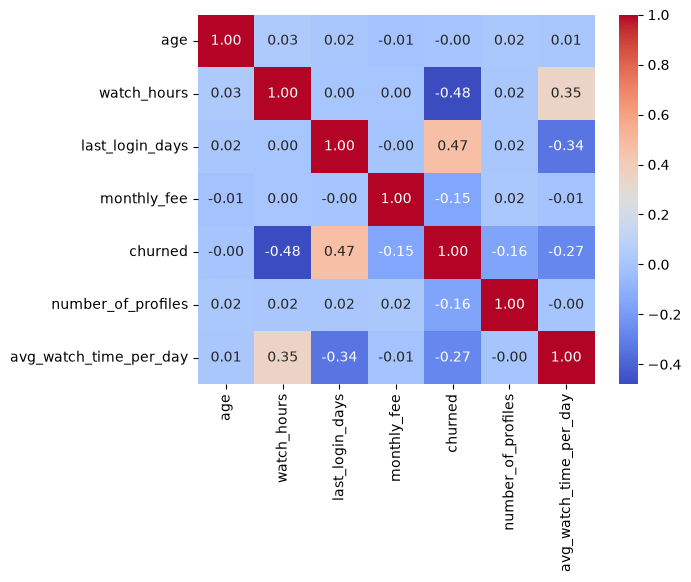

In [24]:
sns.heatmap(df_corr.corr(), annot=True, cmap="coolwarm",fmt=".2f")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

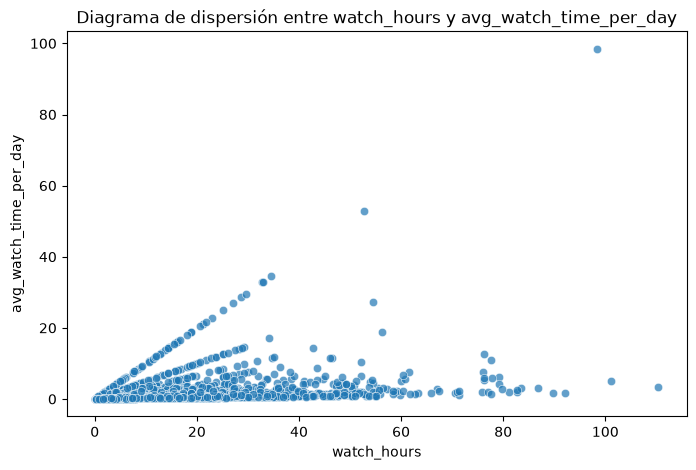

In [26]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="watch_hours",y="avg_watch_time_per_day",alpha=0.7)
plt.title("Diagrama de dispersión entre watch_hours y avg_watch_time_per_day")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

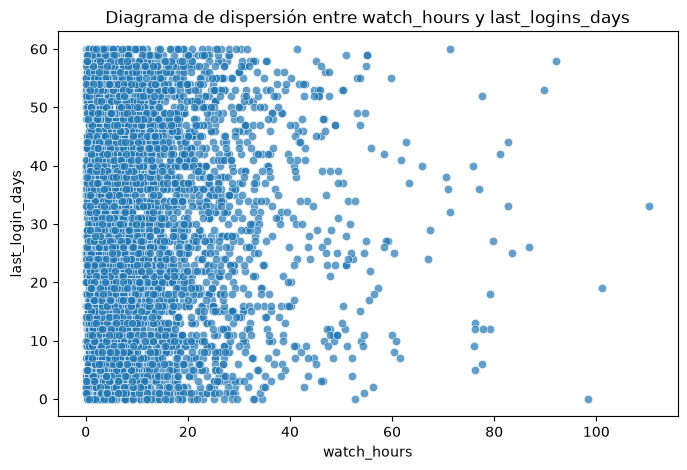

In [28]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="watch_hours",y="last_login_days",alpha=0.7)
plt.title("Diagrama de dispersión entre watch_hours y last_logins_days")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

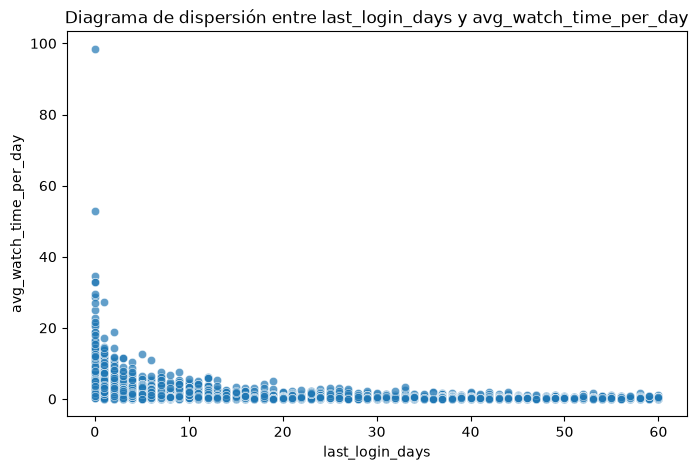

In [29]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="last_login_days",y="avg_watch_time_per_day",alpha=0.7)
plt.title("Diagrama de dispersión entre last_login_days y avg_watch_time_per_day")
plt.show

Variables categóricas vs TARGET

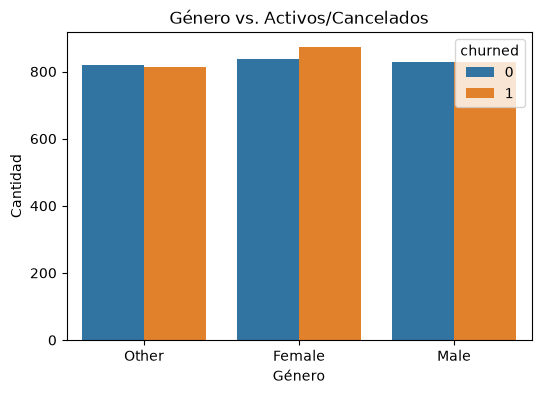

In [123]:
# No se evidencia que el género de los clientes sea un factor sobre el target
plt.figure(figsize=(6,4))
sgraf1=sns.countplot(data=df, x="gender",hue="churned")
sgraf1.set_xlabel("Género")
sgraf1.set_ylabel("Cantidad")
sgraf1.set_title("Género vs. Activos/Cancelados")
plt.show()

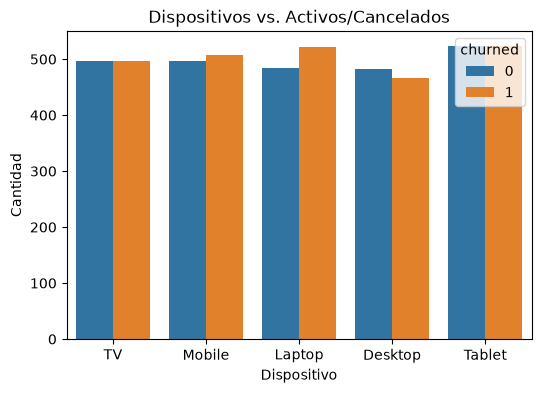

In [125]:
# No se evidencia que el tipo de dispositivo utilizado para la reproducción de streaming sea un factor
plt.figure(figsize=(6,4))
sgraf2=sns.countplot(data=df, x="device",hue="churned")
sgraf2.set_xlabel("Dispositivo")
sgraf2.set_ylabel("Cantidad")
sgraf2.set_title("Dispositivos vs. Activos/Cancelados")
plt.show()

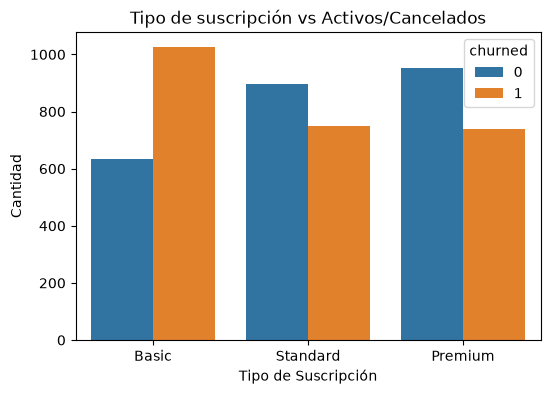

In [126]:
# Las suscripciones mas altas tienen mayor cantidad de clientes activos que cancelados
plt.figure(figsize=(6,4))
sgraf3=sns.countplot(data=df, x="subscription_type", hue="churned")
sgraf3.set_xlabel("Tipo de Suscripción")
sgraf3.set_ylabel("Cantidad")
sgraf3.set_title("Tipo de suscripción vs Activos/Cancelados")
plt.show()

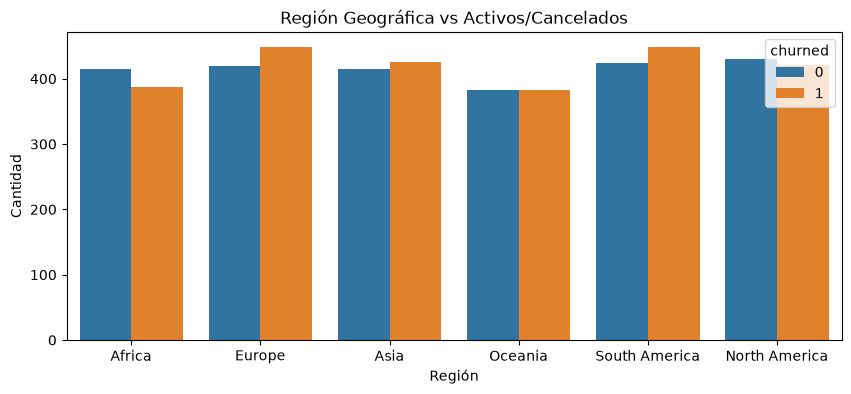

In [128]:
# No se evidencia que la zona geográfica de los mercados primarios tengan diferencias significativas respecto de suscripciones Activas vs Canceladas.
plt.figure(figsize=(10,4))
sgraf4=sns.countplot(data=df, x="region", hue="churned")
sgraf4.set_xlabel("Región")
sgraf4.set_ylabel("Cantidad")
sgraf4.set_title("Región Geográfica vs Activos/Cancelados")
plt.show()

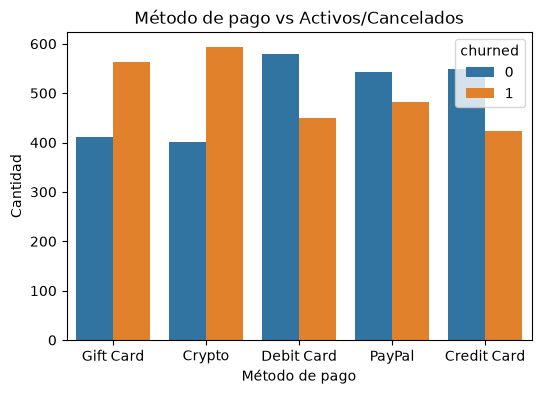

In [129]:
# Los métodos de pago mas tradicionales (Debito, Credito, Paypal), tienen mayor nivel de Activos
# Confirma respecto del contexto del dataset y confirma Hipótesis 3 
plt.figure(figsize=(6,4))
sgraf5=sns.countplot(data=df, x="payment_method", hue="churned")
sgraf5.set_xlabel("Método de pago")
sgraf5.set_ylabel("Cantidad")
sgraf5.set_title("Método de pago vs Activos/Cancelados")
plt.show()

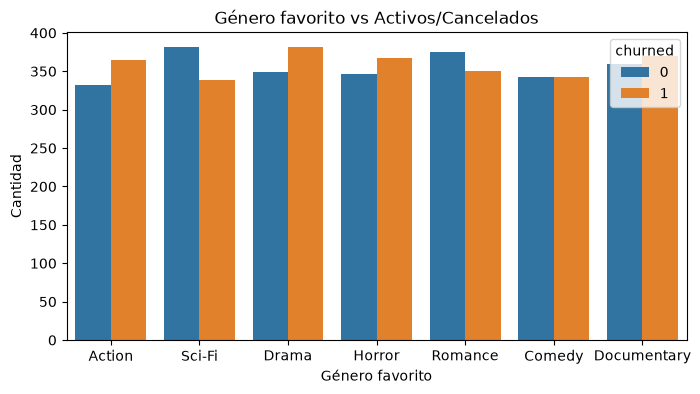

In [130]:
# la propuestas de género de ofertas de streaming no representa un diferencial entre ellos.
plt.figure(figsize=(8,4))
sgraf6=sns.countplot(data=df, x="favorite_genre", hue="churned")
sgraf6.set_xlabel("Género favorito")
sgraf6.set_ylabel("Cantidad")
sgraf6.set_title("Género favorito vs Activos/Cancelados")
plt.show()

Variables numéricas vs. TARGET

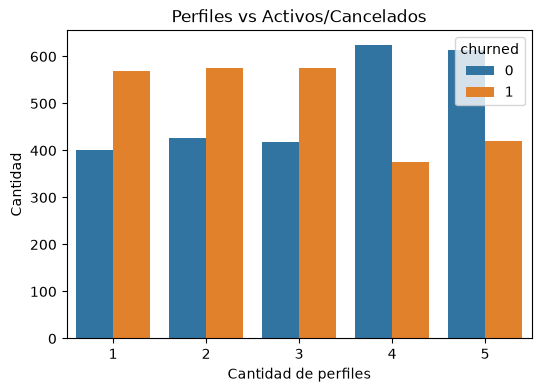

In [132]:
#H4: Perfiles: se verifica Hipótesis 4: los suscriptores con mas perfiles, cancelan menos.
# En particular com mas de 3
plt.figure(figsize=(6,4))
sgraf20=sns.countplot(data=df, x="number_of_profiles",hue="churned")
sgraf20.set_xlabel("Cantidad de perfiles")
sgraf20.set_ylabel("Cantidad")
sgraf20.set_title("Perfiles vs Activos/Cancelados")
plt.show()

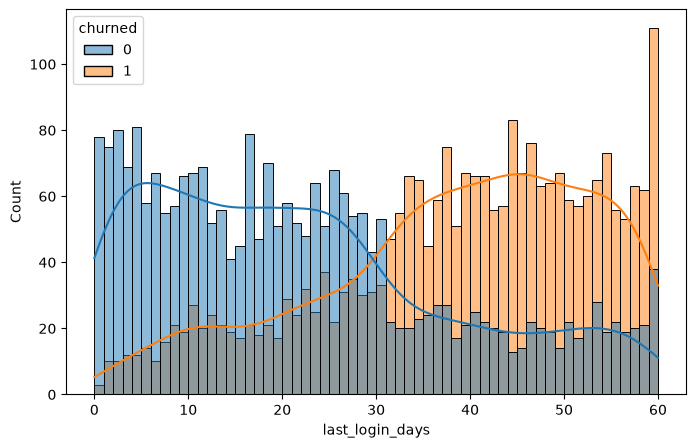

In [142]:
## Después de 30 días aproximadamente, del último login las cancelaciones superan a los activos.
## Confirma Hipótesis 2
plt.figure(figsize=(8,5))
sns.histplot(data=df,x="last_login_days",hue="churned", bins=60, kde=True)
#plt.title("Ultimo login vs. Activo/Cancelado")
plt.show()

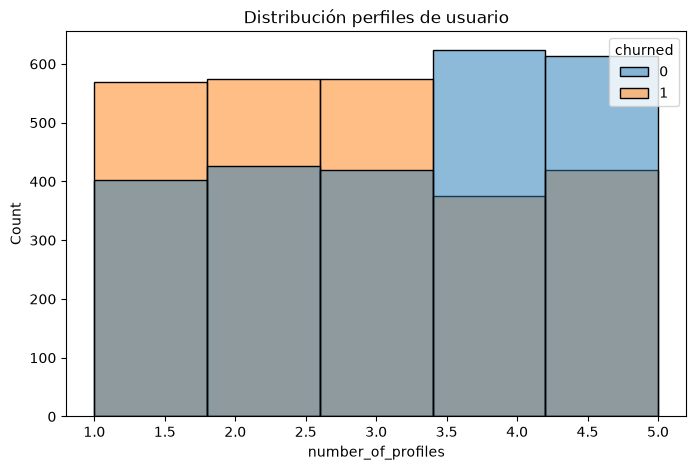

In [144]:
## Las suscripciones con mas de 3 perfiles tienen mayor cantidad de activvos que cancelados
## Confirma Hipótesis 4
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="number_of_profiles", hue="churned", bins = 5)
plt.title("Distribución perfiles de usuario")
plt.show()

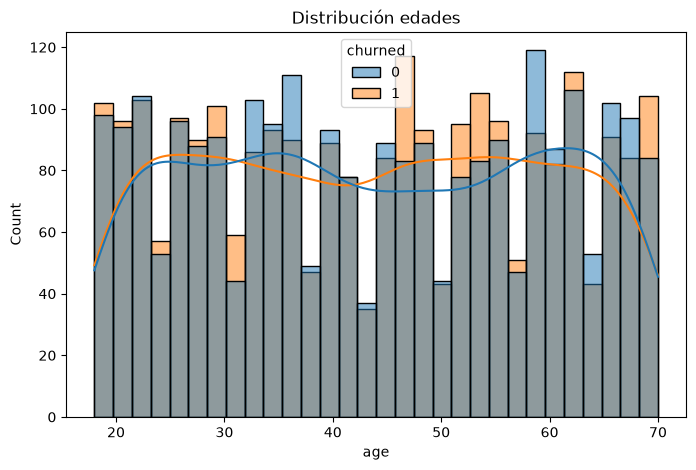

In [152]:
## La influencia de las franjas etareas sobre la retención no parece ser un factor
## Se observa que la distribución es bastante uniforme (con excepciones sobre las primeras ý ultimas edades), a la vez de ser proxima Activos y Cancelados.
## Se observan mejores proporciones de activos entre 32 y 45 años (aproximadamente), y mayor cantidad de Cancelados entre 45 y 55 años (aproximadamente).
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="age", hue="churned", bins = 30, kde=True)
plt.title("Distribución edades")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

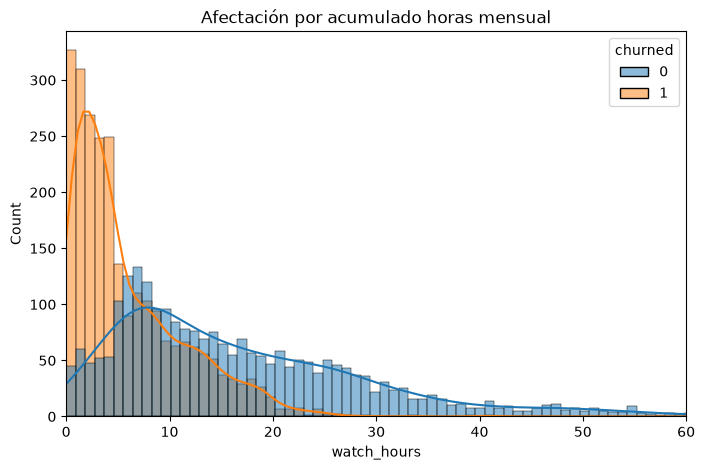

In [140]:
## Verifico relevancias de estas variables respecto de la variable TARGET
## Conclusión: los clientes com menor cantidad de horas mensuales vistas, cancelan mas.
## Confirma Hipótesis 1
plt.figure(figsize=(8,5))
hist_whours=sns.histplot(data=df,x="watch_hours",hue="churned",bins=120,kde=True,color="green",edgecolor="black")
hist_whours.set_title("Afectación por acumulado horas mensual")
hist_whours.set_xlim(0,60)
plt.show

Dependencia respecto de las horas acumuladas mensuales, last_login y Target

<function matplotlib.pyplot.show(close=None, block=None)>

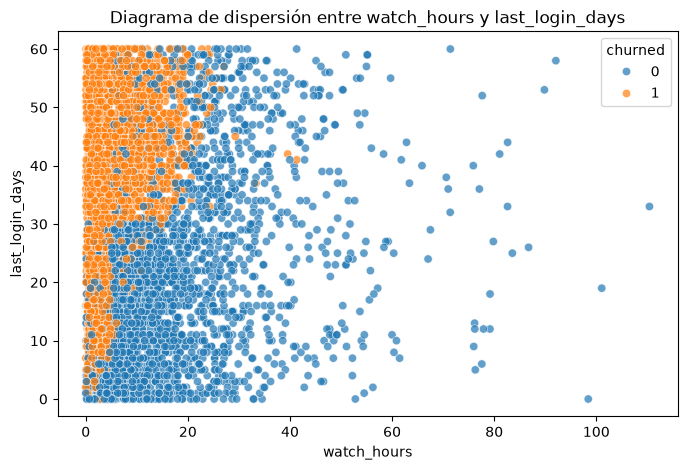

In [154]:
## Se observa una tendencia general respecto del aumento de cancelaciones segun aumenta la cantidad de días del último login y la baja en el acumulado de horas mensual.
## Además de aprecia fuertemente la afectación en el aumento de cancelaciones a partir de los 30 días aproximadamente.
## Sin embargo, y en contro a lo anterior, se observa que existente un grupo, que ante el aumento del tiempo del último login la fidelidad aumenta en gran medida.
plt.figure(figsize=(8,5))
sp_1=sns.scatterplot(data=df,x="watch_hours",y="last_login_days",alpha=0.7,hue="churned")
sp_1.set_title("Diagrama de dispersión entre watch_hours y last_login_days")
plt.show

Analisis de outliers de watch_hours

In [158]:
## Las distribución de esta variable es asimétrica positica y se considerarán los susbriptores con mas de 35 horas acumuladas mensuales
q1,q3=df["watch_hours"].quantile([0.25,0.75])
max=q3+1.5*(q3-q1)
print("Cuartíl Q1: ",q1,"  Cuartil Q3: ",q3,"  MAX:  ", max)

Cuartíl Q1:  3.3375   Cuartil Q3:  16.03   MAX:   35.06875


In [159]:
## Agrego columna outlier_watch_hours como FLAG marcando True a los pertenencientes al grupo de outliers
df["outlier_watch_hours"] = np.where(df["watch_hours"] > max,True,False)
df

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,outlier_watch_hours
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action,False
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi,False
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama,False
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror,False
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama,True
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary,False
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action,False
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi,False


In [195]:
## Los outliers son 238
print(" *** Cantidades *** \n",df.outlier_watch_hours.value_counts())
print("\n *** Porcentajes *** \n",df.outlier_watch_hours.value_counts(normalize=True)*100)


 *** Cantidades *** 
 outlier_watch_hours
False    4762
True      238
Name: count, dtype: int64

 *** Porcentajes *** 
 outlier_watch_hours
False    95.24
True      4.76
Name: proportion, dtype: float64


In [162]:
dfoutliers = df[df["outlier_watch_hours"] == True]
dfoutliers

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,outlier_watch_hours
15,25db8257-f409-4acd-81f8-99629fbf15a0,32,Female,Premium,40.94,7,South America,Desktop,17.99,0,Crypto,1,5.12,Action,True
22,8071c1be-1197-49a1-aa75-5fb6a6b3087a,53,Other,Standard,43.02,43,South America,Tablet,13.99,0,Crypto,1,0.98,Action,True
44,783c7652-37b8-4be0-b8bc-fb51bd4b5578,27,Other,Premium,46.88,56,Oceania,TV,17.99,0,Crypto,3,0.82,Drama,True
49,c9c8202c-992c-4e6c-b04f-0e2961ea87cc,42,Female,Basic,49.49,39,Europe,Mobile,8.99,0,Credit Card,5,1.24,Horror,True
57,09a76bc9-4048-4403-8087-a31cdb16556e,31,Male,Basic,48.35,11,Oceania,Desktop,8.99,0,Debit Card,5,4.03,Comedy,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4962,3160aa58-0bf6-4e81-a1af-51903f0c0588,65,Female,Standard,70.99,36,Oceania,Mobile,13.99,0,Crypto,2,1.92,Horror,True
4968,4d0d9fe7-24e6-423a-909d-9842181b5945,41,Other,Basic,48.84,47,Asia,Tablet,8.99,0,PayPal,4,1.02,Romance,True
4979,c2385a8f-375b-4476-b78d-072cd47b996c,27,Other,Basic,71.38,32,South America,Mobile,8.99,0,PayPal,5,2.16,Comedy,True
4989,b2903ea6-d58c-4ffa-bf43-3e5e6a25ca06,69,Male,Standard,42.72,52,South America,Tablet,13.99,0,Crypto,3,0.81,Drama,True


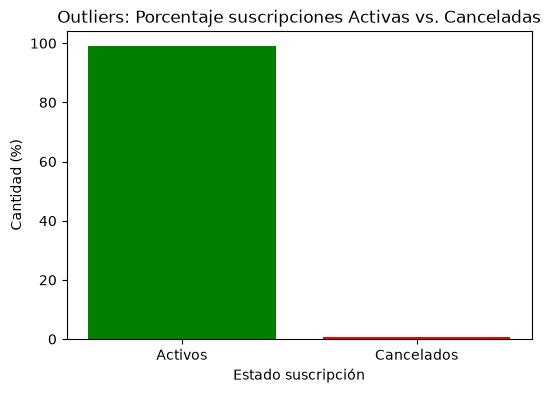

In [174]:
## Outliers: Activos vs Cancelados
plt.figure(figsize=(6,4))
outliers_count = dfoutliers.churned.value_counts(normalize=True)*100
plt.bar(["Activos","Cancelados"],outliers_count,color=["green","red"])
plt.title("Outliers: Porcentaje suscripciones Activas vs. Canceladas")
plt.xlabel("Estado suscripción")
plt.ylabel("Cantidad (%)")
plt.show()

In [175]:
print(outliers_count)

churned
0    99.159664
1     0.840336
Name: proportion, dtype: float64


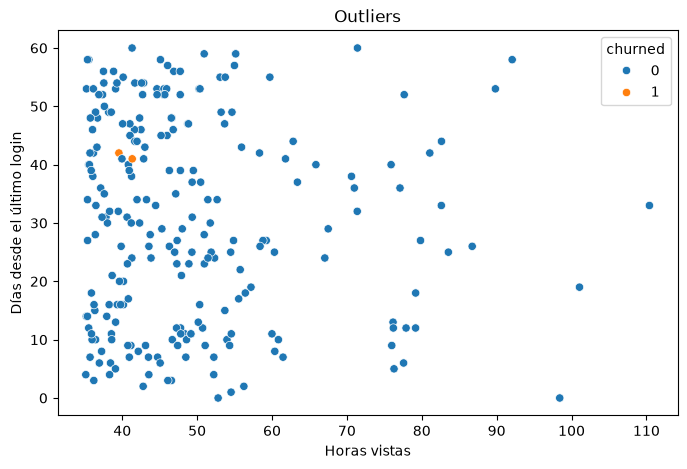

In [176]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=outliers, x="watch_hours", y="last_login_days", hue="churned")
plt.title("Outliers")
plt.xlabel("Horas vistas")
plt.ylabel("Días desde el último login")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

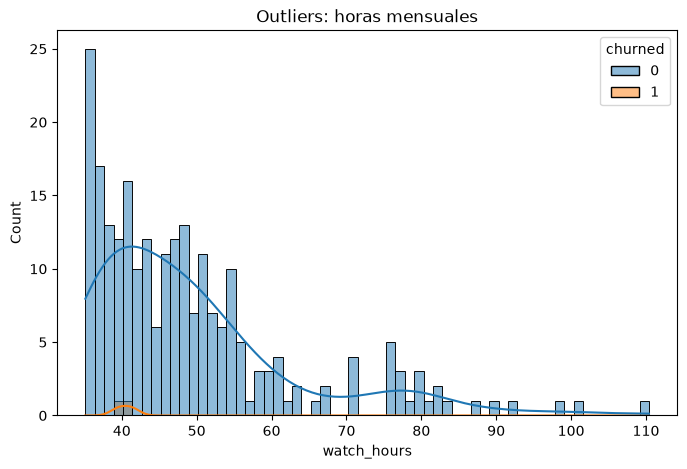

In [177]:
plt.figure(figsize=(8,5))
sns.histplot(data=outliers,x="watch_hours",hue="churned",bins=60,kde=True,color="green",edgecolor="black")
plt.title("Outliers: horas mensuales")
#plt.xlim(0,60)
plt.show